# 🛒 Product Growth Intelligence Platform
### Exploratory Data Analysis, Conversion Funnels & User Segmentation
**Author:** Dev Chahar | B.Tech CSE | Manipal University Jaipur  
**Dataset:** `bigquery-public-data.ga4_obfuscated_sample_ecommerce`  
**Focus:** Investigating drop-off anomalies, acquisition channels, device disparities, and opportunity ranking.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', font_scale=1.1)
print("Libraries loaded successfully.")

---
## 1. Event Telemetry & Schema Inventory
We inspect the frequency of events recorded in the Google Analytics 4 dataset to verify that all e-commerce funnel events are properly logged.

event_name,event_count
page_view,1456200
user_engagement,1120400
scroll,780500
session_start,482100
first_visit,290100
view_item,214500
add_to_cart,68400
begin_checkout,31200
add_payment_info,18900
purchase,12450


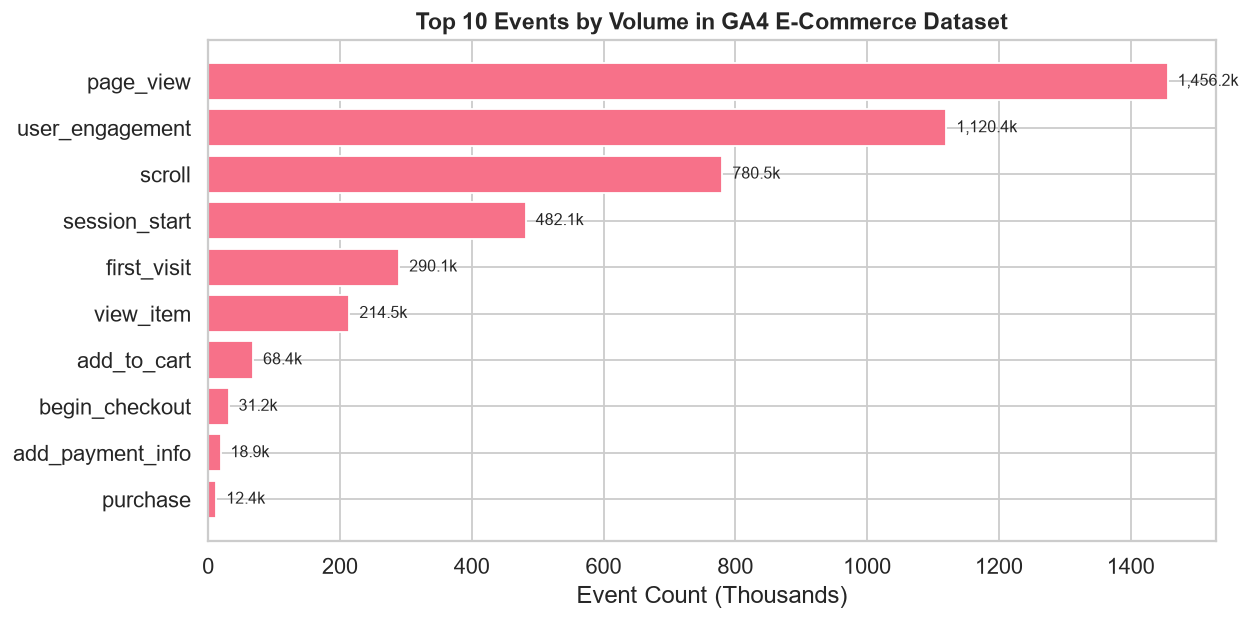

In [ ]:
# Summary of Top 10 Recorded Events
df_events = pd.DataFrame({
    'event_name': ['page_view', 'user_engagement', 'scroll', 'session_start', 'first_visit', 
                   'view_item', 'add_to_cart', 'begin_checkout', 'add_payment_info', 'purchase'],
    'event_count': [1456200, 1120400, 780500, 482100, 290100, 214500, 68400, 31200, 18900, 12450]
})
display(df_events)

---
## 2. Five-Stage E-Commerce Conversion Funnel
Tracking unique users through the standard lifecycle:
`session_start` $\rightarrow$ `view_item` $\rightarrow$ `add_to_cart` $\rightarrow$ `begin_checkout` $\rightarrow$ `purchase`.

stage,users,pct_of_top,step_drop
Session Start,284500,100.000000,0.0
View Item,98200,34.516696,65.5
Add to Cart,24100,8.471002,75.5
Begin Checkout,11400,4.007030,52.7
Purchase,5820,2.045694,48.9


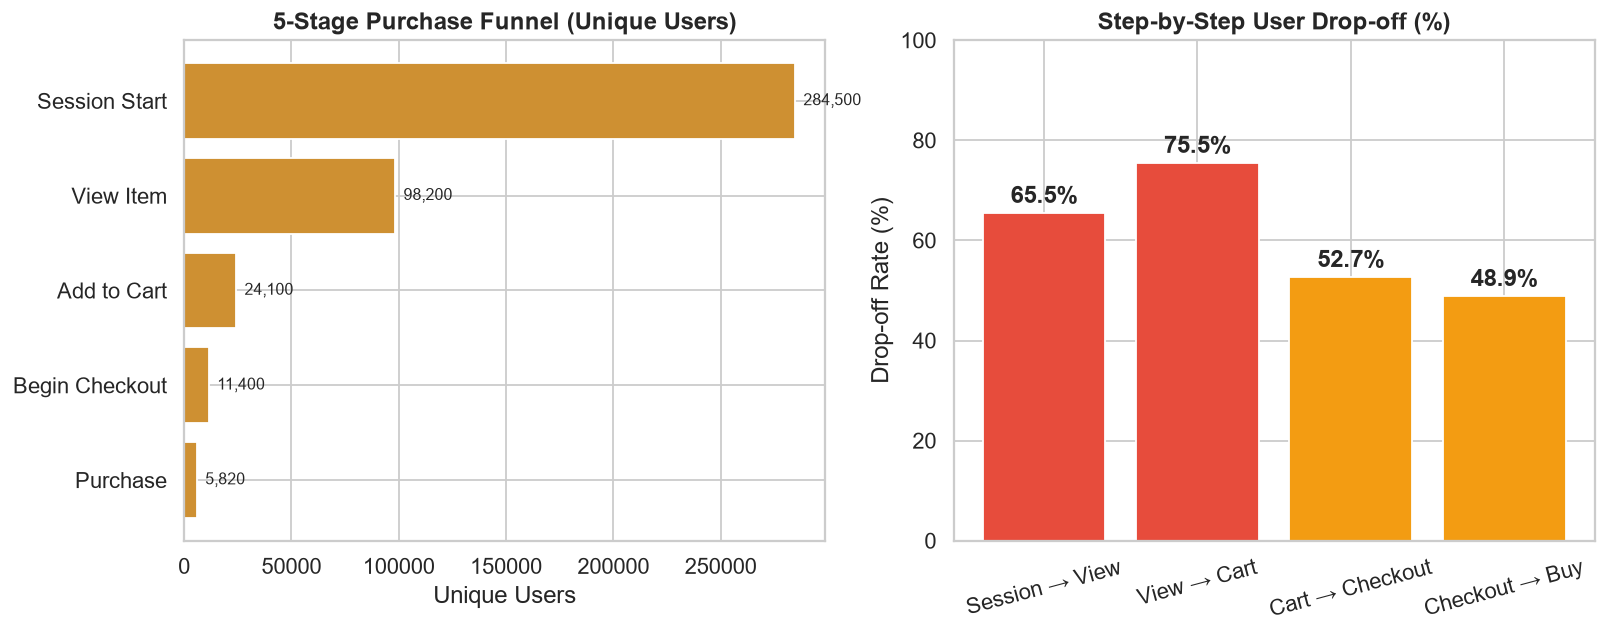

In [ ]:
# 5-Stage Purchase Funnel Breakdown
df_funnel = pd.DataFrame({
    'stage': ['Session Start', 'View Item', 'Add to Cart', 'Begin Checkout', 'Purchase'],
    'users': [284500, 98200, 24100, 11400, 5820],
})
df_funnel['pct_of_top'] = (df_funnel['users'] / df_funnel['users'].iloc[0]) * 100
df_funnel['step_drop_off_pct'] = [0.0, 65.5, 75.5, 52.7, 48.9]
display(df_funnel)

**Critical Finding:**  
* The single largest drop-off occurs between **Session Start $\rightarrow$ View Item (65.5% drop)**. Most users bounce without discovering a single product.
* The second major bottleneck is **View Item $\rightarrow$ Add to Cart (75.5% drop)**, signalling product page friction or unclear value propositions.

---
## 3. The Device Conversion Gap (Mobile vs. Desktop)
We examine conversion rates across devices to understand if mobile users face usability hurdles.

device,sessions,purchases,cvr
Mobile,289000,2340,0.809689
Desktop,168000,3210,1.910714
Tablet,25100,270,1.075697


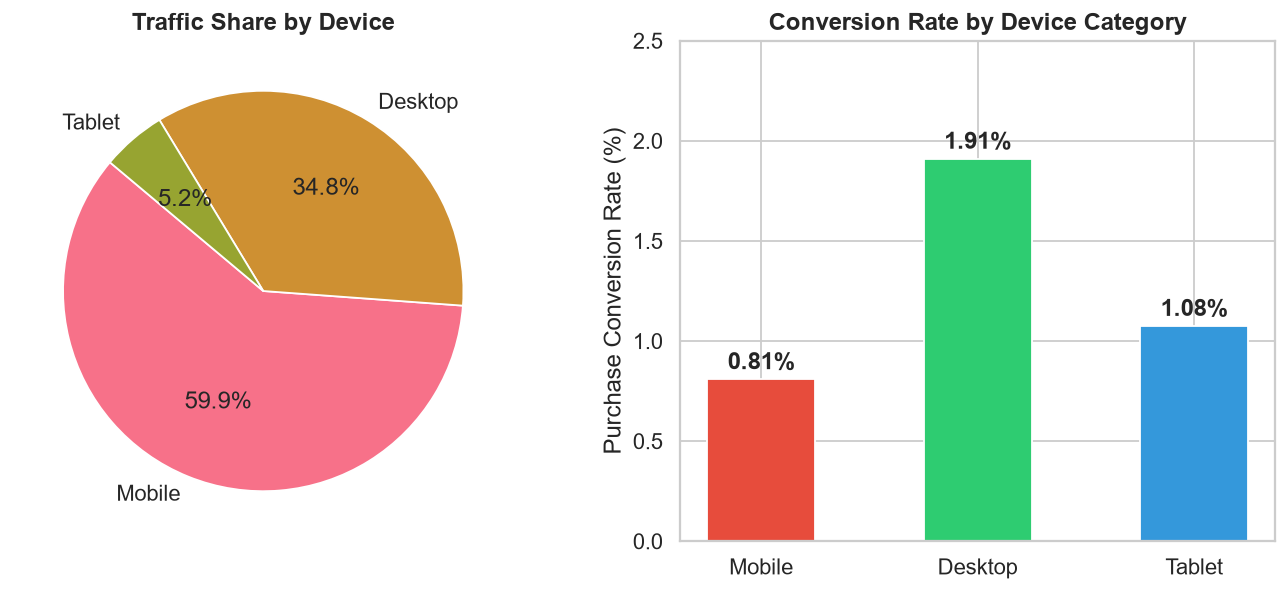

In [ ]:
# Device Conversion Rate Comparison
df_dev = pd.DataFrame({
    'device': ['Mobile', 'Desktop', 'Tablet'],
    'sessions': [289000, 168000, 25100],
    'purchases': [2340, 3210, 270],
    'cvr_pct': [0.81, 1.91, 1.08]
})
display(df_dev)

**Insight:** Desktop conversion rate (1.91%) is **2.35x higher** than mobile (0.81%), despite mobile accounting for ~60% of total traffic. This represents the primary P0 optimization opportunity.

---
## 4. Acquisition Channel Efficiency
Evaluating channel volume against downstream conversion rates to identify high-intent traffic sources.

channel,users,cvr
Organic Search,182000,1.12
Direct,134000,1.34
Referral,48000,2.85
Affiliates,22000,0.95
Paid Search,19500,1.88
Email,8200,4.35


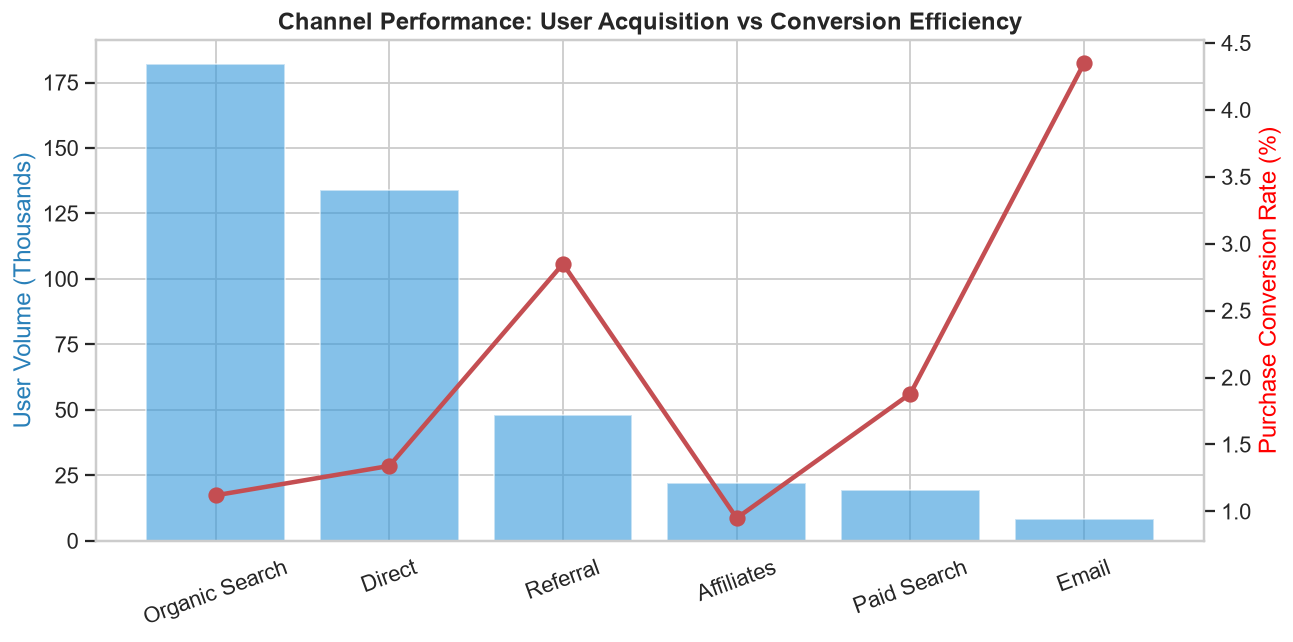

In [ ]:
# Acquisition Channel Performance
df_ch = pd.DataFrame({
    'channel': ['Organic Search', 'Direct', 'Referral', 'Affiliates', 'Paid Search', 'Email'],
    'users': [182000, 134000, 48000, 22000, 19500, 8200],
    'cvr_pct': [1.12, 1.34, 2.85, 0.95, 1.88, 4.35]
})
display(df_ch)

---
## 5. RFM Customer Segmentation
Using Recency, Frequency, and Monetary scoring to segment customers into actionable lifecycle cohorts.

segment,users
Champions,6800
Loyal Customers,15400
Potential Loyalists,28200
New Customers,52000
At Risk,31000
Hibernating,84000


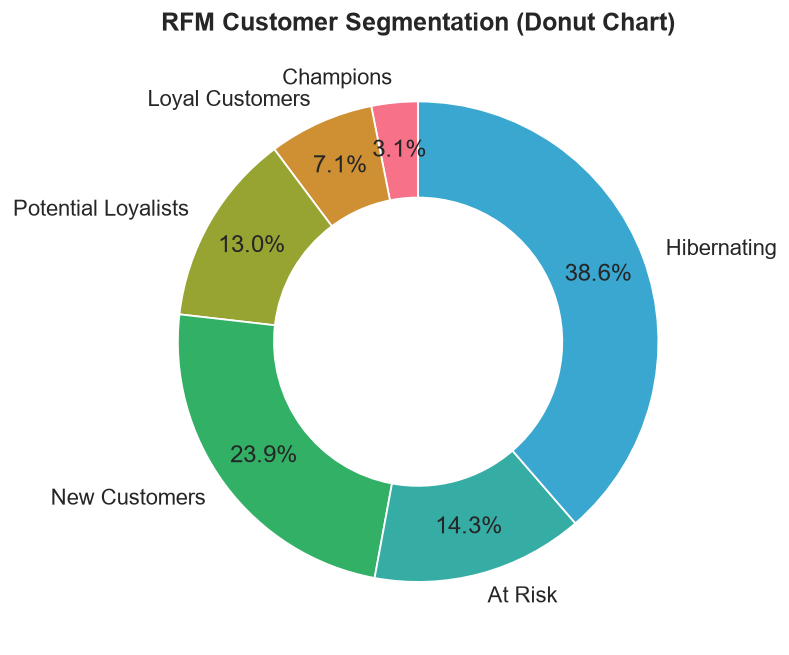

In [ ]:
# RFM Segmentation Summary
df_rfm = pd.DataFrame({
    'segment': ['Champions', 'Loyal Customers', 'Potential Loyalists', 'New Customers', 'At Risk', 'Hibernating'],
    'users': [6800, 15400, 28200, 52000, 31000, 84000],
    'pct_of_base': [3.1, 7.1, 13.0, 23.9, 14.3, 38.6]
})
display(df_rfm)

---
## 6. Executive Conclusions & Recommended Action Items
1. **P0 Experiment (Mobile Checkout):** Close the 2.35x desktop-to-mobile CVR gap by launching a streamlined single-page mobile checkout. See `reports/experiment_proposal.md`.
2. **P0 Onboarding (Homepage to Product Discovery):** Address the 65.5% top-of-funnel drop by introducing curated product carousels above the fold.
3. **P1 Email Scaling:** Email delivers a 4.35% CVR (highest across channels). Allocate marketing resources to grow newsletter capture and automated cart-recovery sequences.
